# Факторы риска болезни сердца

Команда № 82

Участники:
- Гневко Софья, группа 8
- Дук Никита, группа 10


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (log_loss, roc_auc_score, roc_curve, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

from scipy import stats
from scipy.stats import shapiro, mannwhitneyu
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

## 1. Описание данных

Тема - диагностика болезни сердца. По результатам обследования нужно понять, есть ли у пациента сужение коронарных артерий.

Наблюдение - один пациент клиники Cleveland Clinic Foundation (США).

Источник - UCI Machine Learning Repository, набор Heart Disease, https://www.kaggle.com/datasets/cherngs/heart-disease-cleveland-uci

Целевой признак - condition (1 есть болезнь сердца, 0 нет).

In [4]:
df=pd.read_csv('heart_cleveland_upload.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [3]:
df.shape

(297, 14)

В данных 297 наблюдений и 14 признаков: 13 предикторов и целевой признак condition.

## 2. Описание признаков

In [5]:
df.dtypes

age            int64
sex            int64
cp             int64
trestbps       int64
chol           int64
fbs            int64
restecg        int64
thalach        int64
exang          int64
oldpeak      float64
slope          int64
ca             int64
thal           int64
condition      int64
dtype: object

| Признак | Описание | Формат | Тип |
|---|---|---|---|
| age | возраст, лет | int64 | количественный дискретный |
| sex | пол (1 мужчина, 0 женщина) | int64 | категориальный бинарный |
| cp | тип боли в груди (0 типичная стенокардия, 1 атипичная стенокардия, 2 неангинозная боль, 3 боли нет) | int64 | категориальный номинальный |
| trestbps | давление в покое, мм рт. ст. | int64 | количественный непрерывный |
| chol | холестерин, мг/дл | int64 | количественный непрерывный |
| fbs | сахар натощак больше 120 мг/дл (1 да, 0 нет) | int64 | категориальный бинарный |
| restecg | ЭКГ в покое (0 норма, 1 изменения ST-T, 2 гипертрофия левого желудочка) | int64 | категориальный номинальный |
| thalach | максимальный пульс при нагрузке, ударов в минуту | int64 | количественный дискретный |
| exang | стенокардия при нагрузке (1 да, 0 нет) | int64 | категориальный бинарный |
| oldpeak | депрессия сегмента ST при нагрузке, мм | float64 | количественный непрерывный |
| slope | наклон сегмента ST (0 восходящий, 1 плоский, 2 нисходящий) | int64 | категориальный порядковый |
| ca | число крупных сосудов, окрашенных при флюороскопии (от 0 до 3) | int64 | количественный дискретный |
| thal | таллиевый тест (0 норма, 1 стойкий дефект, 2 обратимый дефект) | int64 | категориальный номинальный|
| condition | болезнь сердца (1 есть, 0 нет), целевой признак | int64 | категориальный бинарный |

Все признаки записаны числами, но у sex, cp, fbs, restecg, exang, slope, thal и condition числа это только коды категорий. Поэтому эти признаки категориальные, хотя формат у них int64.

## 3. Пропуски и дубликаты

In [6]:
df.isna().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
condition    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

Пропусков и дубликатов нет. Сохраняем данные в новую переменную df_clean и дальше работаем с ней.

In [8]:
df_clean=df.drop_duplicates()
df_clean.shape

(297, 14)

### Расшифровка кодов категорий

Заменим коды категорий на названия, чтобы на графиках было понятно, где какая категория. condition оставляем числом 0 и 1, он нужен для модели. После замены у этих признаков формат object.

In [9]:
sex_names={0: 'female', 1: 'male'}
cp_names={0: 'typical', 1: 'atypical', 2: 'non-anginal', 3: 'asymptomatic'}
yes_no={0: 'no', 1: 'yes'}
restecg_names={0: 'normal', 1: 'st-t', 2: 'lvh'}
slope_names={0: 'up', 1: 'flat', 2: 'down'}
thal_names={0: 'normal', 1: 'fixed', 2: 'reversible'}

df_clean['sex']=df_clean['sex'].apply(lambda x: sex_names[x])
df_clean['cp']=df_clean['cp'].apply(lambda x: cp_names[x])
df_clean['fbs']=df_clean['fbs'].apply(lambda x: yes_no[x])
df_clean['restecg']=df_clean['restecg'].apply(lambda x: restecg_names[x])
df_clean['exang']=df_clean['exang'].apply(lambda x: yes_no[x])
df_clean['slope']=df_clean['slope'].apply(lambda x: slope_names[x])
df_clean['thal']=df_clean['thal'].apply(lambda x: thal_names[x])
df_clean.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,male,typical,160,234,yes,lvh,131,no,0.1,flat,1,normal,0
1,69,female,typical,140,239,no,normal,151,no,1.8,up,2,normal,0
2,66,female,typical,150,226,no,normal,114,no,2.6,down,0,normal,0
3,65,male,typical,138,282,yes,lvh,174,no,1.4,flat,1,normal,1
4,64,male,typical,110,211,no,lvh,144,yes,1.8,flat,0,normal,0


## 4. Выбросы

### Ящики с усами

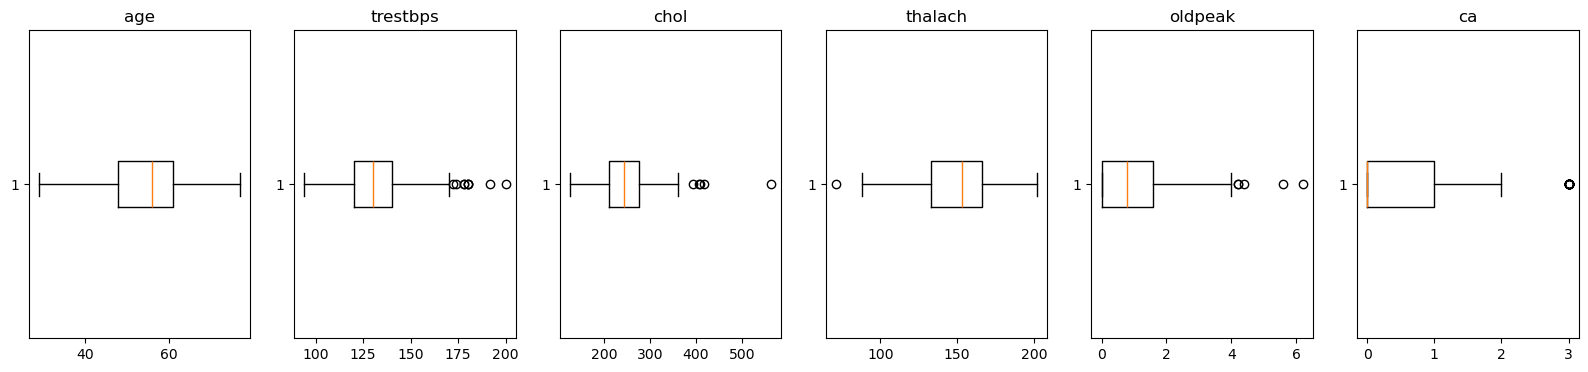

In [10]:
col_num=['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']  # количественные признаки
fig, ax=plt.subplots(1, 6, figsize=(20, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    ax[i].boxplot(df_clean[col_num[i]], vert=False);

Выбросы есть у trestbps (давление выше 170), chol (выше 370), thalach (одно значение ), oldpeak (выше 4) и ca (значение 3). У age выбросов нет. Значение 3 у ca выбросом не считаем, это обычное число сосудов из диапазона от 0 до 3.

### Метод N стандартных отклонений

Этим методом чистим давление trestbps, берем N=3. При N=2 граница была бы 167 и удалилось бы 15 человек, хотя давление 170-180 у таких пациентов встречается часто.

In [11]:
avg=df_clean['trestbps'].mean()
std=df_clean['trestbps'].std()
left=avg-3*std
right=avg+3*std
left, right

(np.float64(78.40518359380567), np.float64(184.9820217933997))

In [12]:
df_clean[df_clean['trestbps'].between(left, right)==False]  # выбросы

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
45,54,male,atypical,192,283,no,lvh,195,no,0.0,up,1,reversible,1
234,56,female,asymptomatic,200,288,yes,lvh,133,yes,4.0,down,2,reversible,1


In [13]:
df_std=df_clean[df_clean['trestbps'].between(left, right)]
df_std.shape

(295, 14)

Границы получились от 78.41 до 184.98. Удалили 2 пациентов с давлением 192 и 200. Результат сохраняем в новую переменную df_std, в ней 295 строк.

### Метод 1.5 IQR

Этим методом чистим холестерин chol. Берем уже очищенный df_std. 

In [14]:
Q1=df_std['chol'].quantile(0.25)
Q3=df_std['chol'].quantile(0.75)
IQR=Q3-Q1
left=Q1-1.5*IQR
right=Q3+1.5*IQR
left, right

(np.float64(115.0), np.float64(371.0))

In [15]:
df_std[df_std['chol'].between(left, right)==False]  # выбросы

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
79,67,female,non-anginal,115,564,no,lvh,160,no,1.6,flat,0,reversible,0
83,65,female,non-anginal,140,417,yes,lvh,157,no,0.8,up,1,normal,0
180,63,female,asymptomatic,150,407,no,lvh,154,no,4.0,flat,3,reversible,1
188,62,female,asymptomatic,140,394,no,lvh,157,no,1.2,flat,0,normal,0
238,56,female,asymptomatic,134,409,no,lvh,150,yes,1.9,flat,2,reversible,1


In [16]:
df_iqr=df_std[df_std['chol'].between(left, right)]
df_iqr.shape

(290, 14)

Границы получились от 115 до 371. Удалили 5 пациентов с холестерином 564, 417, 409, 407 и 394. Результат сохраняем в новую переменную df_iqr, в ней 290 строк. Дальше все делаем на df_iqr.

## 5. Визуализация

### Гистограммы количественных признаков

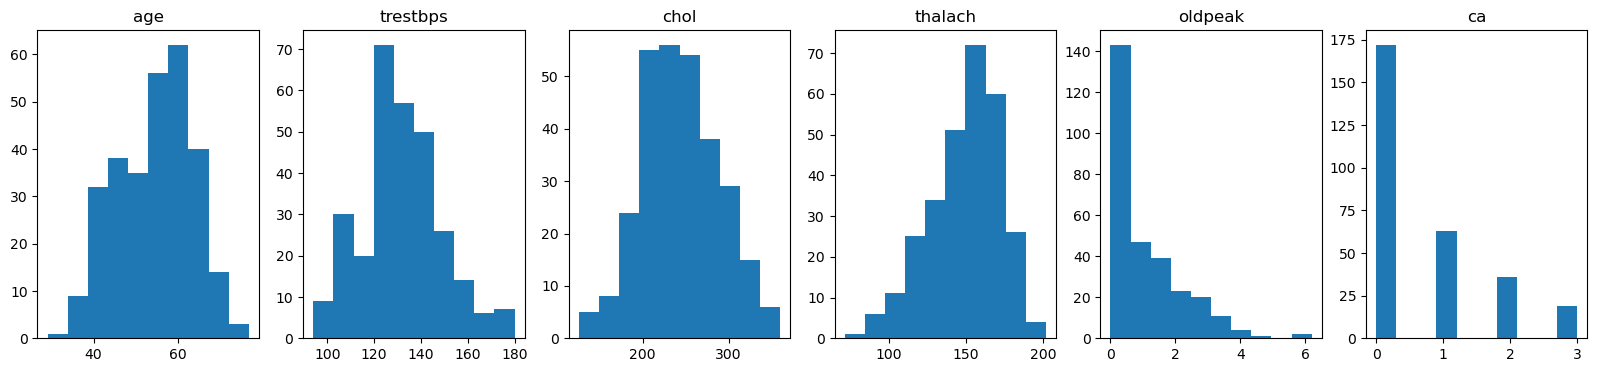

In [17]:
fig, ax=plt.subplots(1, 6, figsize=(20, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    ax[i].hist(df_iqr[col_num[i]]);

- age - распределение почти симметричное, немного скошено влево. Больше всего пациентов в возрасте 53-62 лет, самым молодым около 30.
- trestbps - скошено вправо, пик на 120-130. 
- chol - после чистки почти симметричное, в основном от 200 до 280.
- thalach - скошено влево, у большинства пульс 150-170.
- oldpeak - сильно скошено вправо, почти у половины пациентов значение около 0, максимум 6.2.
- ca - всего четыре значения, чаще всего 0, дальше все реже.

### Столбчатые диаграммы категориальных признаков

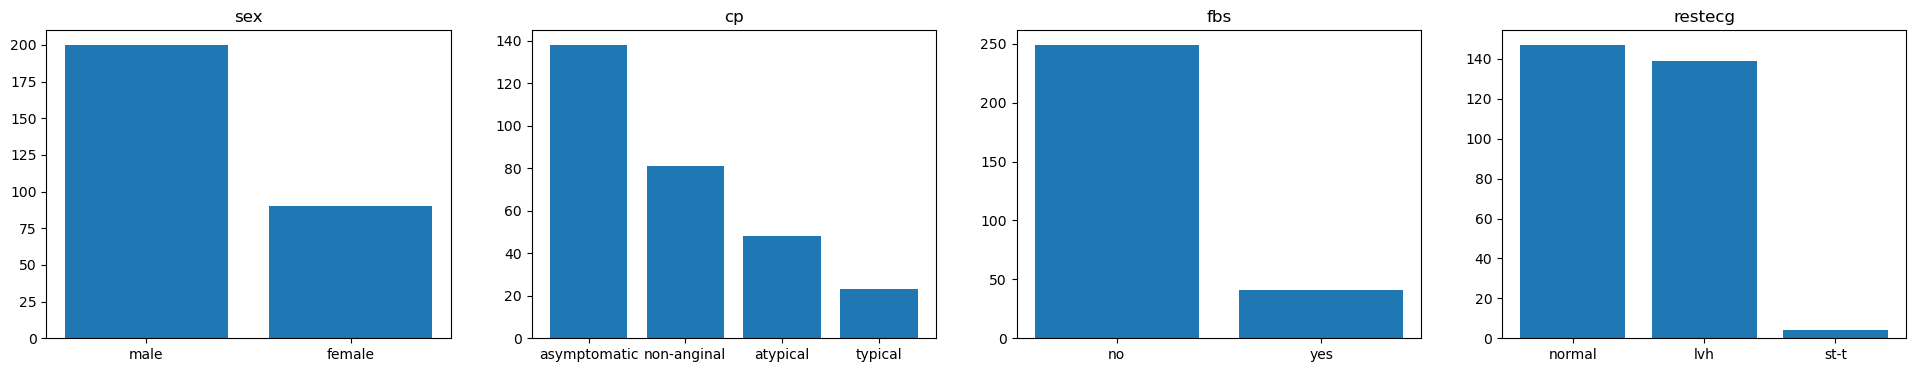

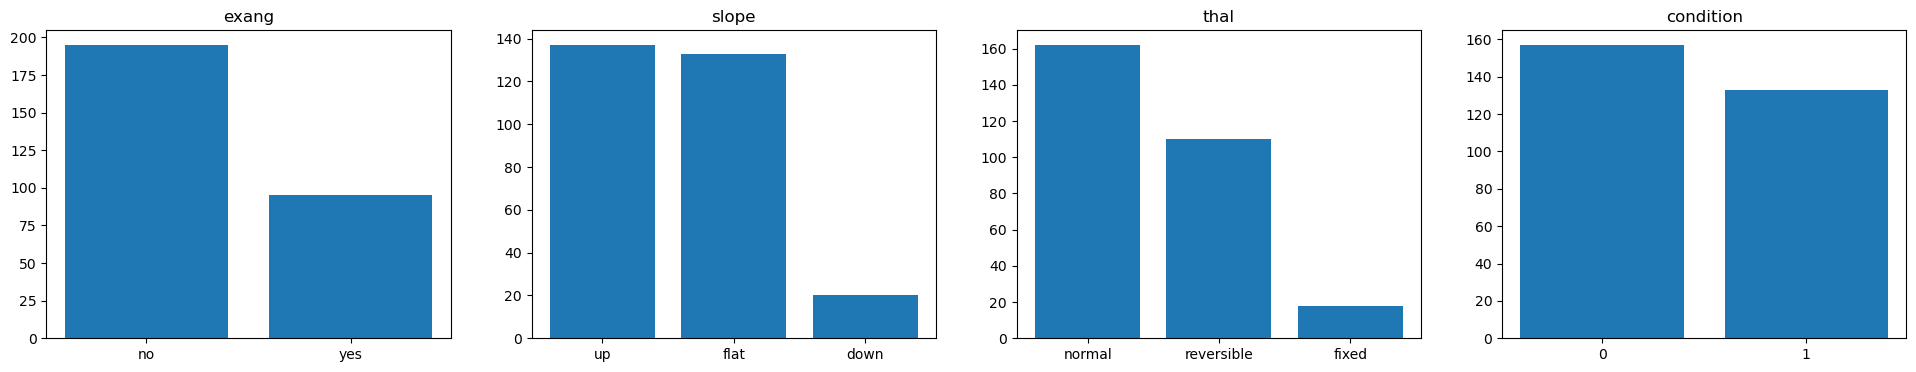

In [18]:
col_cat=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal', 'condition']  # категориальные признаки
fig, ax=plt.subplots(1, 4, figsize=(24, 4))
for i in range(4):
    ax[i].set_title(col_cat[i])
    freq=df_iqr[col_cat[i]].value_counts()
    ax[i].bar(freq.index.astype(str), freq.values);
fig, ax=plt.subplots(1, 4, figsize=(24, 4))
for i in range(4):
    ax[i].set_title(col_cat[i+4])
    freq=df_iqr[col_cat[i+4]].value_counts()
    ax[i].bar(freq.index.astype(str), freq.values);

In [22]:
for col in col_cat:
    print(df_iqr[col].value_counts())

sex
male      200
female     90
Name: count, dtype: int64
cp
asymptomatic    138
non-anginal      81
atypical         48
typical          23
Name: count, dtype: int64
fbs
no     249
yes     41
Name: count, dtype: int64
restecg
normal    147
lvh       139
st-t        4
Name: count, dtype: int64
exang
no     195
yes     95
Name: count, dtype: int64
slope
up      137
flat    133
down     20
Name: count, dtype: int64
thal
normal        162
reversible    110
fixed          18
Name: count, dtype: int64
condition
0    157
1    133
Name: count, dtype: int64


- sex - мужчин больше: 200 против 90.
- cp - чаще всего asymptomatic (138, это 48%), то есть боли в груди нет. Реже всего typical: 23.
- fbs - у большинства сахар в норме: 249 против 41.
- restecg - normal (147) и lvh (139) почти поровну, st-t всего у 4 человек.
- exang - стенокардия при нагрузке у 95 из 290, примерно у трети.
- slope - up (137) и flat (133) почти поровну, down всего 20.
- thal - чаще normal (162) и reversible (110), fixed всего 18.
- condition - 157 здоровых и 133 больных, классы почти сбалансированы.

### Скрипичные графики

Для количественных признаков по оси x класс condition (0 здоров, 1 болен), по оси y значения признака.

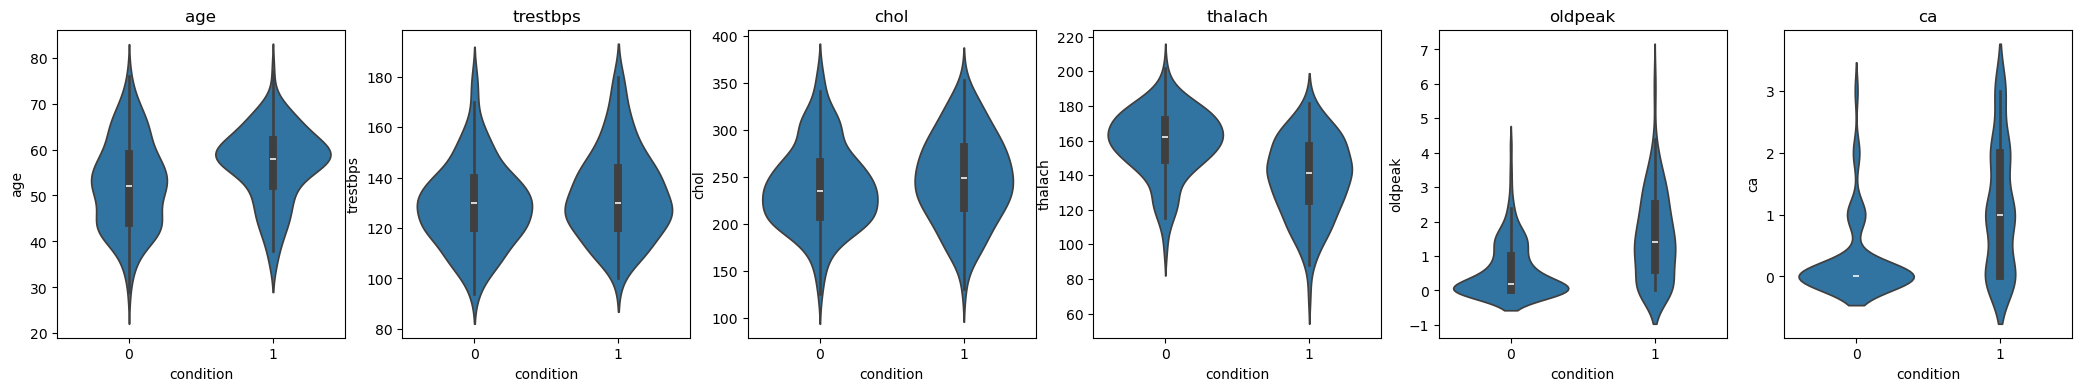

In [24]:
fig, ax=plt.subplots(1, 6, figsize=(26, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    sns.violinplot(data=df_iqr, x='condition', y=col_num[i], ax=ax[i])

In [25]:
df_iqr.groupby('condition')[col_num].median()

,age,trestbps,chol,thalach,oldpeak,ca
condition,,,,,,
0,52.0,130.0,235.0,162.0,0.2,0.0
1,58.0,130.0,249.0,141.0,1.4,1.0


- age - больные старше: медиана 58 лет против 52 у здоровых.
- trestbps - скрипки почти одинаковые, медиана 130 в обеих группах, связи не видно.
- chol - у больных медиана чуть выше (249 и 235), связь слабая.
- thalach - у больных пульс ниже: медиана 141 против 162.
- oldpeak - у здоровых почти все значения около 0 (медиана 0.2), у больных медиана 1.4.
- ca - у здоровых почти везде 0, у больных от 0 до 3, медиана 1.

Для категориальных признаков наоборот: по оси x категория, по оси y condition. Чем толще скрипка вверху у 1, тем больше больных в этой категории.

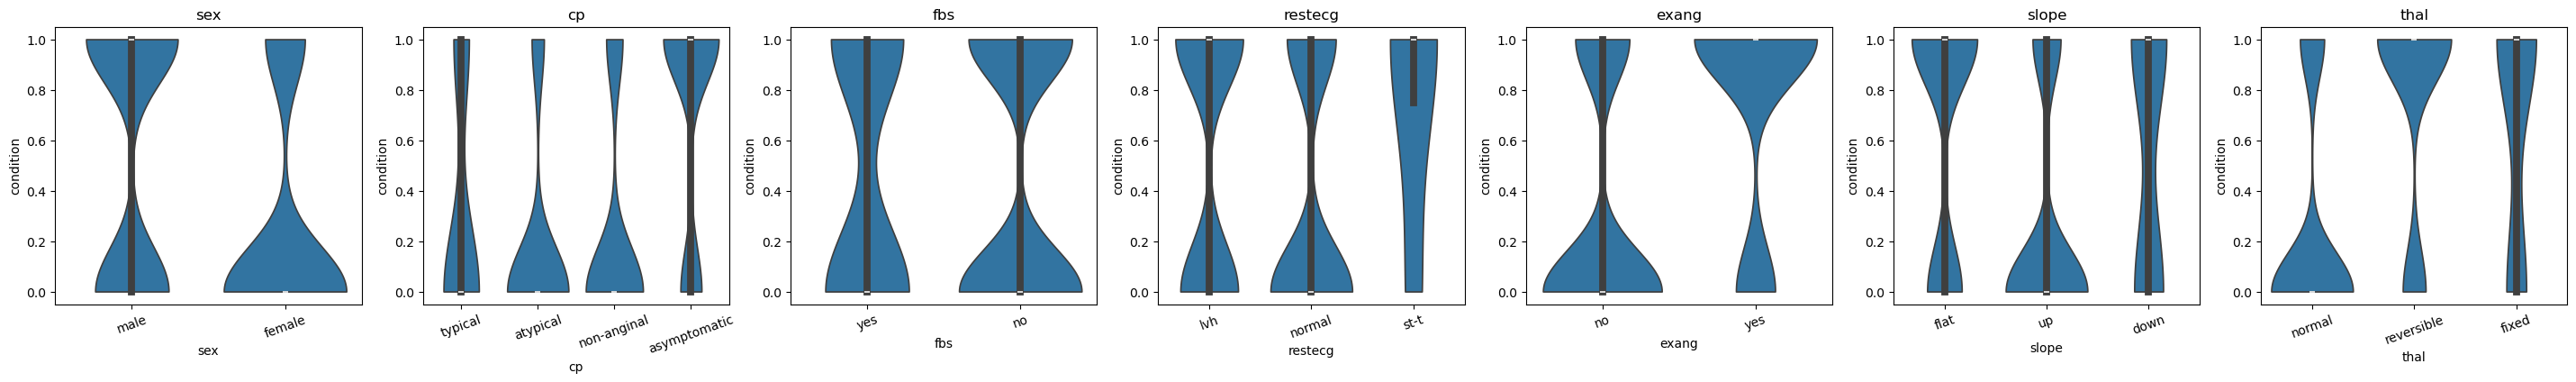

In [26]:
col_pred_cat=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']  # категориальные предикторы
fig, ax=plt.subplots(1, 7, figsize=(36, 4))
for i in range(len(col_pred_cat)):
    ax[i].set_title(col_pred_cat[i])
    sns.violinplot(data=df_iqr, x=col_pred_cat[i], y='condition', cut=0, ax=ax[i])
    ax[i].tick_params(axis='x', labelrotation=20)

In [27]:
for col in col_pred_cat:
    print(df_iqr.groupby(col)['condition'].mean().round(2))

sex
female    0.24
male      0.56
Name: condition, dtype: float64
cp
asymptomatic    0.72
atypical        0.17
non-anginal     0.22
typical         0.30
Name: condition, dtype: float64
fbs
no     0.46
yes    0.46
Name: condition, dtype: float64
restecg
lvh       0.54
normal    0.37
st-t      0.75
Name: condition, dtype: float64
exang
no     0.31
yes    0.76
Name: condition, dtype: float64
slope
down    0.55
flat    0.65
up      0.26
Name: condition, dtype: float64
thal
fixed         0.67
normal        0.23
reversible    0.76
Name: condition, dtype: float64


- sex - болеют 56% мужчин и 24% женщин.
- cp - при asymptomatic больных 72%, при остальных типах боли 17-30%.
- fbs - доля больных 46% в обеих группах, связи нет.
- restecg - при lvh больных 54%, при normal 37%. В группе st-t всего 4 человека, по ней выводов не делаем.
- exang - при стенокардии при нагрузке больных 76%, без нее 31%.
- slope - при up больных 26%, при flat 65%, при down 55%.
- thal - при normal больных 23%, при reversible 76%, при fixed 67%.

## 6. Описательные статистики

### Целевой признак

condition бинарный, поэтому смотрим частоты, моду, число уникальных значений и среднее. У признака из 0 и 1 среднее равно доле единиц. Медиана и дисперсия для него не подходят.

In [28]:
df_iqr['condition'].value_counts()

condition
0    157
1    133
Name: count, dtype: int64

In [29]:
print('доля больных:', round(df_iqr['condition'].mean(), 2))
print('мода:', df_iqr['condition'].mode()[0])
print('количество уникальных значений:', df_iqr['condition'].nunique())

доля больных: 0.46
мода: 0
количество уникальных значений: 2


- 157 здоровых (54%) и 133 больных (46%).
- Доля больных 0.46.
- Мода 0, здоровых немного больше.
- Уникальных значений 2.
- Классы почти сбалансированы, поэтому accuracy для модели подходит, но смотреть будем и другие метрики.

### Количественные признаки

In [30]:
df_iqr[col_num].describe().round(2)

,age,trestbps,chol,thalach,oldpeak,ca
count,290.00,290.00,290.00,290.00,290.00,290.00
mean,54.40,131.18,243.80,149.40,1.03,0.66
std,9.08,17.07,45.24,23.02,1.15,0.93
min,29.00,94.00,126.00,71.00,0.00,0.00
25%,47.25,120.00,211.00,132.25,0.00,0.00
50%,55.50,130.00,240.00,152.00,0.80,0.00
75%,61.00,140.00,273.75,166.00,1.60,1.00
max,77.00,180.00,360.00,202.00,6.20,3.00


In [31]:
pd.DataFrame({'median': df_iqr[col_num].median(),
              'IQR': df_iqr[col_num].quantile(0.75)-df_iqr[col_num].quantile(0.25),
              'range': df_iqr[col_num].max()-df_iqr[col_num].min()})

,median,IQR,range
age,55.5,13.75,48.0
trestbps,130.0,20.00,86.0
chol,240.0,62.75,234.0
thalach,152.0,33.75,131.0
oldpeak,0.8,1.60,6.2
ca,0.0,1.00,3.0


- age - средний возраст 54.4, медиана 55.5. Стандартное отклонение 9.08. Половина пациентов в возрасте от 47.25 до 61 года (IQR 13.75), размах 48 (от 29 до 77).
- trestbps - среднее 131.18, медиана 130. Стандартное отклонение 17.07. IQR 20 (от 120 до 140), размах 86 (от 94 до 180).
- chol - среднее 243.8, медиана 240, они близки, поэтому распределение почти симметричное. Стандартное отклонение 45.24, IQR 62.75 (от 211 до 273.75), размах 234 (от 126 до 360).
- thalach - среднее 149.4, медиана 152. Медиана больше среднего, значит скос влево. Стандартное отклонение 23.02, IQR 33.75 (от 132.25 до 166), размах 131 (от 71 до 202).
- oldpeak - среднее 1.03, медиана 0.8, среднее больше из-за хвоста справа. Q1 равен 0, то есть у четверти пациентов депрессии ST нет. IQR 1.6, размах 6.2.
- ca - медиана 0 и Q1 тоже 0, значит больше чем у половины пациентов окрашенных сосудов нет. Q3 равен 1, максимум 3, среднее 0.66.

### Категориальные признаки

Для них считаем количество, число уникальных значений, моду (top) и ее частоту (freq).

In [32]:
df_iqr[col_pred_cat].describe()

,sex,cp,fbs,restecg,exang,slope,thal
count,290,290,290,290,290,290,290
unique,2,4,2,3,2,3,3
top,male,asymptomatic,no,normal,no,up,normal
freq,200,138,249,147,195,137,162


- sex - 2 значения, мода male, 200 из 290 (69%).
- cp - 4 значения, мода asymptomatic, 138 (48%).
- fbs - 2 значения, мода no, 249 (86%).
- restecg - 3 значения, мода normal, 147 (51%).
- exang - 2 значения, мода no, 195 (67%).
- slope - 3 значения, мода up, 137 (47%).
- thal - 3 значения, мода normal, 162 (56%).

## 7. Перекодирование данных

Берем df_iqr, результат сохраняем в новую переменную df_encoded.

### One-Hot для бинарных признаков

In [33]:
df_encoded=pd.get_dummies(df_iqr, columns=['sex', 'fbs', 'exang'], drop_first=True, dtype=int)
df_encoded.head()

,age,cp,trestbps,chol,restecg,thalach,oldpeak,slope,ca,thal,condition,sex_male,fbs_yes,exang_yes
0,69,typical,160,234,lvh,131,0.1,flat,1,normal,0,1,1,0
1,69,typical,140,239,normal,151,1.8,up,2,normal,0,0,0,0
2,66,typical,150,226,normal,114,2.6,down,0,normal,0,0,0,0
3,65,typical,138,282,lvh,174,1.4,flat,1,normal,1,1,1,0
4,64,typical,110,211,lvh,144,1.8,flat,0,normal,0,1,0,1


sex, fbs и exang стали столбцами из 0 и 1. drop_first=True убирает первую категорию, иначе второй столбец повторял бы первый. Остались sex_male, fbs_yes и exang_yes. dtype=int нужен, чтобы были 0 и 1, а не True и False.

### LabelEncoder для номинальных признаков

In [34]:
lst=['cp', 'restecg', 'thal']
for col in lst:
    df_encoded[f'{col}_encoded']=LabelEncoder().fit_transform(df_encoded[col])
for col in lst:
    print(df_encoded[[col, f'{col}_encoded']].drop_duplicates().sort_values(f'{col}_encoded'))

               cp  cp_encoded
155  asymptomatic           0
23       atypical           1
72    non-anginal           2
0         typical           3
   restecg  restecg_encoded
0      lvh                0
1   normal                1
72    st-t                2
         thal  thal_encoded
6       fixed             0
0      normal             1
5  reversible             2


LabelEncoder нумерует категории по алфавиту, например у cp: asymptomatic 0, atypical 1, non-anginal 2, typical 3. Порядка у этих категорий нет, поэтому сравнивать коды как больше и меньше нельзя.

### OrdinalEncoder для порядкового признака

In [35]:
encoder=OrdinalEncoder(categories=[['up', 'flat', 'down']])
df_encoded['slope_encoded']=encoder.fit_transform(df_encoded[['slope']]).astype(int)
df_encoded[['slope', 'slope_encoded']].drop_duplicates().sort_values('slope_encoded')

,slope,slope_encoded
1,up,0
0,flat,1
2,down,2


slope порядковый: up это норма, flat хуже, down еще хуже. Порядок задали сами через categories: up 0, flat 1, down 2. Без этого коды встали бы по алфавиту.

## 8. Корреляция

Считаем коэффициент Спирмена: целевой признак бинарный, есть порядковые коды и скошенные признаки, а Спирмен устойчив к выбросам.

### Парная корреляция condition и thalach

In [36]:
df_encoded['condition'].corr(df_encoded['thalach'], method='spearman')

np.float64(-0.4373256769445296)

Коэффициент -0.44. Связь обратная: у больных пульс при нагрузке ниже. По модулю 0.44, это между 0.3 и 0.7, значит связь умеренная. Спирмен показывает монотонную связь, и о причине она ничего не говорит.

### Корреляционная матрица

Оставляем только связь каждого признака с condition.

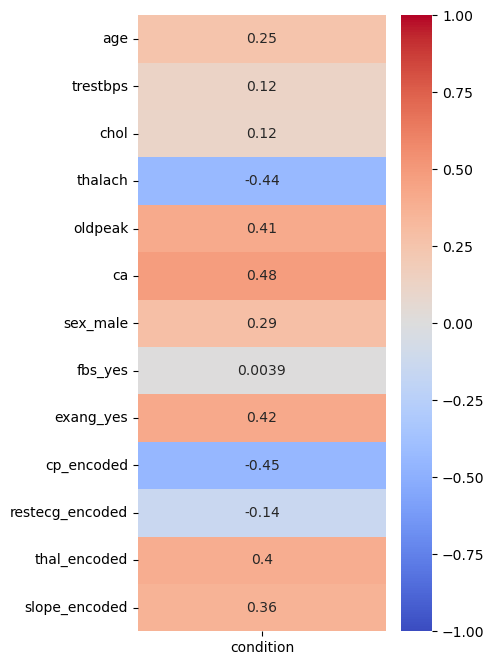

In [37]:
col_corr=['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex_male', 'fbs_yes', 'exang_yes',
          'cp_encoded', 'restecg_encoded', 'thal_encoded', 'slope_encoded', 'condition']
corr_target=df_encoded[col_corr].corr(method='spearman')[['condition']].drop('condition')
plt.figure(figsize=(4, 8))
sns.heatmap(corr_target, annot=True, vmin=-1, vmax=1, cmap='coolwarm');

### Топ-5 признаков по силе связи с condition

In [38]:
corr_target['condition'].abs().sort_values(ascending=False).head(5)

ca            0.483352
cp_encoded    0.449851
thalach       0.437326
exang_yes     0.419214
oldpeak       0.413968
Name: condition, dtype: float64

1. ca 0.48 - умеренная прямая связь, чем больше окрашенных сосудов, тем чаще болезнь.
2. cp_encoded -0.45 - умеренная связь, минус из-за алфавитных кодов (у asymptomatic код 0, а больных там 72%).
3. thalach -0.44 - умеренная обратная связь.
4. exang_yes 0.42 - умеренная прямая связь.
5. oldpeak 0.41 - умеренная прямая связь.

Слабее всего с болезнью связаны fbs_yes (0.00), chol (0.12) и trestbps (0.12).

### Выбор предикторов

Из топ-5 берем ca, thalach, exang_yes и oldpeak. cp_encoded не берем: коды стоят по алфавиту, и вес при нем не объяснить. thal_encoded (0.40) не берем по той же причине. slope_encoded (0.36) связан с oldpeak на 0.59, поэтому вместо него берем sex_male (0.29). Проверим мультиколлинеарность.

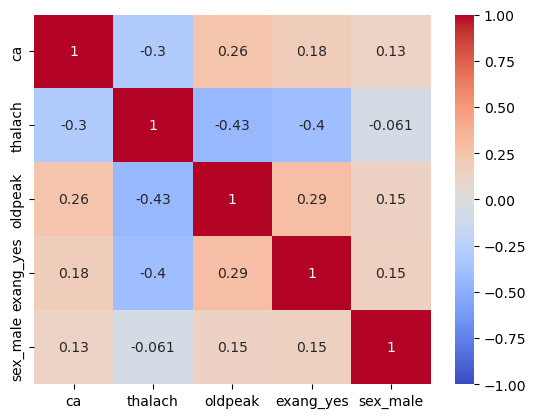

In [39]:
col_model=['ca', 'thalach', 'oldpeak', 'exang_yes', 'sex_male']
sns.heatmap(df_encoded[col_model].corr(method='spearman'), annot=True, vmin=-1, vmax=1, cmap='coolwarm');

Самая сильная связь между предикторами -0.43 (thalach и oldpeak), по модулю меньше 0.7, мультиколлинеарности нет.

## 9. Масштабирование данных

Нормализуем количественные признаки через StandardScaler: вычитаем среднее и делим на стандартное отклонение. Результат сохраняем в новую переменную df_scaled. Бинарные столбцы, коды категорий и condition не трогаем.

In [41]:
df_scaled=df_encoded.copy()
df_scaled[col_num]=StandardScaler().fit_transform(df_scaled[col_num])
df_scaled[col_num].describe().round(2)

,age,trestbps,chol,thalach,oldpeak,ca
count,290.00,290.00,290.00,290.00,290.00,290.00
mean,0.00,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.80,-2.18,-2.61,-3.41,-0.90,-0.71
25%,-0.79,-0.66,-0.73,-0.75,-0.90,-0.71
50%,0.12,-0.07,-0.08,0.11,-0.20,-0.71
75%,0.73,0.52,0.66,0.72,0.49,0.36
max,2.49,2.86,2.57,2.29,4.50,2.51


Теперь у количественных признаков среднее 0 и стандартное отклонение 1, поэтому их веса в модели сравнимы между собой.

## 10. Регрессия

### Описание модели

Мы хотим построить модель, которая предсказывает вероятность болезни сердца (condition=1) по пяти признакам: ca, thalach, oldpeak, exang_yes и sex_male. Целевой признак бинарный, поэтому строим логистическую регрессию. Количественные признаки берем нормализованные.

### Деление выборки

In [42]:
X=df_scaled[['ca', 'thalach', 'oldpeak', 'exang_yes', 'sex_male']]
Y=df_scaled['condition']
X_train, X_test, y_train, y_test=train_test_split(X, Y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((232, 5), (58, 5))

Делим 80 на 20: 232 пациента в тренировочной выборке и 58 в тестовой. random_state=42, чтобы разбиение не менялось при перезапуске.

### Обучение модели

In [44]:
model=LogisticRegression().fit(X_train, y_train)

In [45]:
print('w0:', model.intercept_.round(2))
print(pd.Series(model.coef_[0], index=X.columns).round(2))

w0: [-1.27]
ca           0.88
thalach     -0.60
oldpeak      0.58
exang_yes    1.23
sex_male     1.13
dtype: float64


### Уравнение модели

$z=-1.27+0.88 \cdot ca-0.60 \cdot thalach+0.58 \cdot oldpeak+1.23 \cdot exang\_yes+1.13 \cdot sex\_male$

$P(condition=1)=\frac{1}{1+e^{-z}}$

ca, thalach и oldpeak здесь нормализованные.

In [47]:
pd.Series(np.exp(model.coef_[0]), index=X.columns).round(2)  # во сколько раз меняются шансы

ca           2.40
thalach      0.55
oldpeak      1.79
exang_yes    3.40
sex_male     3.11
dtype: float64

### Интерпретация коэффициентов

Знак веса показывает, растет вероятность болезни или падает. e в степени веса показывает, во сколько раз меняются шансы болезни.

- w0 = -1.27 - у женщины без стенокардии при нагрузке и со средними ca, thalach и oldpeak вероятность болезни 0.22.
- ca = 0.88 - если число сосудов растет на одно стандартное отклонение (примерно 0.93 сосуда), вероятность болезни растет при прочих равных. Шансы растут в 2.40 раза.
- thalach = -0.60 - если пульс растет на одно стандартное отклонение (примерно 23 удара), вероятность болезни падает при прочих равных. Шансы умножаются на 0.55, то есть падают на 45%.
- oldpeak = 0.58 - если депрессия ST растет на одно стандартное отклонение (примерно 1.15 мм), вероятность болезни растет при прочих равных. Шансы растут в 1.79 раза.
- exang_yes = 1.23 - при стенокардии при нагрузке вероятность болезни выше, чем без нее, при прочих равных. Шансы больше в 3.40 раза.
- sex_male = 1.13 - у мужчин вероятность болезни выше, чем у женщин, при прочих равных. Шансы больше в 3.11 раза.

### Метрики качества на тестовой выборке

In [48]:
y_pred_proba=model.predict_proba(X_test)
print('log loss:', round(log_loss(y_test, y_pred_proba), 2))
print('ROC-AUC:', round(roc_auc_score(y_test, y_pred_proba[:, 1]), 2))

log loss: 0.4
ROC-AUC: 0.9


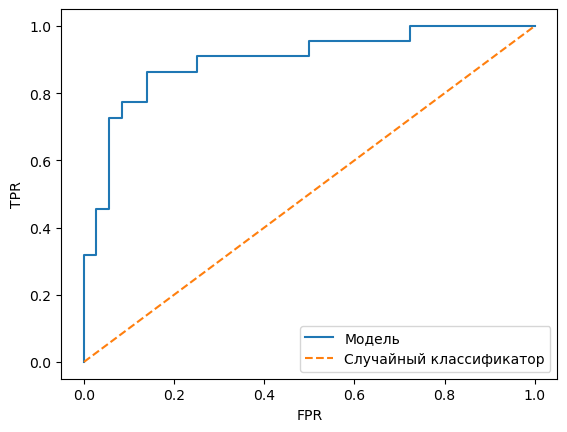

In [49]:
fpr, tpr, thresholds=roc_curve(y_test, y_pred_proba[:, 1])
plt.plot(fpr, tpr, label='Модель')
plt.plot([0, 1], [0, 1], ls='--', label='Случайный классификатор')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend();

In [50]:
y_class=model.predict(X_test)
confusion_matrix(y_test, y_class)

array([[33,  3],
       [ 5, 17]])

In [51]:
print('accuracy:', round(accuracy_score(y_test, y_class), 2))
print('precision:', round(precision_score(y_test, y_class), 2))
print('recall:', round(recall_score(y_test, y_class), 2))
print('F1:', round(f1_score(y_test, y_class), 2))

accuracy: 0.86
precision: 0.85
recall: 0.77
F1: 0.81


In [52]:
print('accuracy на тренировочной:', round(accuracy_score(y_train, model.predict(X_train)), 2))
print('ROC-AUC на тренировочной:', round(roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]), 2))

accuracy на тренировочной: 0.79
ROC-AUC на тренировочной: 0.89


- Матрица ошибок [[33, 3], [5, 17]] - из 36 здоровых модель верно определила 33 (TN), 3 ошибочно назвала больными (FP). Из 22 больных нашла 17 (TP), 5 пропустила (FN).
- Accuracy 0.86 - модель правильно определила 86% пациентов. Если бы всем ставили здоров, было бы 62% (36 из 58).
- Precision 0.85 - из 20 пациентов, которых модель назвала больными, больны 17.
- Recall 0.77 - модель нашла 77% больных. В медицине пропустить больного хуже, чем ложная тревога, поэтому recall тут важнее.
- F1 0.81 - баланс precision и recall, ближе к 1, это хороший результат.
- Log loss 0.40 - чем меньше, тем лучше. Если бы всем давали вероятность 0.5, было бы 0.69.
- ROC-AUC 0.90 - кривая сильно выше диагонали, модель хорошо отличает больных от здоровых и работает лучше случайного угадывания.
- На тренировочной выборке accuracy 0.79 и ROC-AUC 0.89, на тестовой не хуже, переобучения нет.

## 11. Тестирование гипотез

Уровень значимости берем 5%, выводы пишем еще для 1% и 10%. Тесты делаем на df_iqr, там признаки в исходных единицах.

### Проверка нормальности

Тест Шапиро-Уилка, H0: распределение нормальное. Наблюдений 290, это в пределах от 50 до 5000.

In [45]:
for col in col_num:
    print(col, round(shapiro(df_iqr[col])[1], 4))

age 0.0088
trestbps 0.0
chol 0.2043
thalach 0.0001
oldpeak 0.0
ca 0.0


Нормальность не отвергается только у chol (p-value 0.20 > 0.05). У остальных признаков p-value меньше 0.05. Поэтому средние сравниваем по холестерину, а для пульса берем тест Манна-Уитни.

### Тест 1. Одновыборочный Z-тест

Проверяем, что средний холестерин пациентов равен 240 мг/дл (это граница высокого холестерина). Считаем, что выборочная дисперсия равна дисперсии генеральной совокупности. Холестерин распределен нормально (p-value 0.20), наблюдений больше 30.

$H_0: \mu_{chol}=240$

$H_1: \mu_{chol} \neq 240$

In [46]:
res=ztest(df_iqr['chol'], value=240, alternative='two-sided')
res

(np.float64(1.4290293422129416), np.float64(0.15299580008356214))

Вывод: Z = 1.43, p-value = 0.153. Это больше 0.10, поэтому H0 не отвергаем на уровнях 1%, 5% и 10%. Средний холестерин (243.8) значимо от 240 не отличается.

### Тест 2. Одновыборочный t-тест

Проверяем, что у больных средний холестерин больше 240 мг/дл. Дисперсия генеральной совокупности неизвестна, поэтому t-тест. Сначала проверим нормальность у больных.

In [47]:
sick=df_iqr[df_iqr['condition']==1]['chol']
shapiro(sick)[1]

np.float64(0.7236657452035808)

p-value 0.72 > 0.05, нормальность есть.

$H_0: \mu_{chol, ill}=240$

$H_1: \mu_{chol, ill}>240$

In [48]:
res=stats.ttest_1samp(sick, popmean=240, alternative='greater')
res

TtestResult(statistic=np.float64(2.2395006426638107), pvalue=np.float64(0.013398228491205602), df=np.int64(132))

Вывод: t = 2.24, p-value = 0.013. На уровнях 5% и 10% H0 отвергаем, на 1% нет. На уровне 5% средний холестерин больных значимо больше 240 (выборочное среднее 249).

### Тест 3. Парный t-тест

Хотели бы проверить, что у одних и тех же пациентов давление после лечения ниже, чем до лечения.

$H_0: \mu_{before}=\mu_{after}$

$H_1: \mu_{before}>\mu_{after}$

Но этот тест провести нельзя. Парный t-тест нужен для связанных выборок, то есть для двух замеров одного и того же у одних и тех же людей, например до и после лечения. У нас каждый пациент обследован один раз, повторных замеров нет. Разные признаки (давление, холестерин, пульс) измеряют разные вещи в разных единицах, и пары из них не составить. Поэтому тест не проводим.

### Тест 4. Двухвыборочный t-тест

Проверяем, что средний холестерин у женщин и мужчин разный. Выборки независимые. Проверим нормальность в группах и дисперсии.

In [53]:
female=df_iqr[df_iqr['sex']=='female']['chol']
male=df_iqr[df_iqr['sex']=='male']['chol']
print('Шапиро-Уилк, женщины:', round(shapiro(female)[1], 4))
print('Шапиро-Уилк, мужчины:', round(shapiro(male)[1], 4))
print('средние:', round(female.mean(), 2), round(male.mean(), 2))
print('дисперсии:', round(female.var(), 1), round(male.var(), 1))

Шапиро-Уилк, женщины: 0.5356
Шапиро-Уилк, мужчины: 0.6107
средние: 252.17 240.03
дисперсии: 2444.8 1833.3


Шапиро-Уилк: у женщин 0.54, у мужчин 0.61, нормальность есть в обеих группах. Дисперсии 2444.8 и 1833.3 отличаются в 1.3 раза, считаем их равными (equal_var=True).

$H_0: \mu_{female}=\mu_{male}$

$H_1: \mu_{female} \neq \mu_{male}$

In [54]:
res=stats.ttest_ind(female, male, alternative='two-sided', equal_var=True)
res

TtestResult(statistic=np.float64(2.1262735484974167), pvalue=np.float64(0.03433087690328984), df=np.float64(288.0))

Вывод: t = 2.13, p-value = 0.034. На уровнях 5% и 10% H0 отвергаем, на 1% нет. На уровне 5% холестерин у женщин и мужчин различается, у женщин он выше (252.17 и 240.03).

### Тест 5. U-тест Манна-Уитни

Проверяем, что у больных максимальный пульс ниже, чем у здоровых. Выборки независимые. Сначала проверим нормальность.

In [55]:
healthy=df_iqr[df_iqr['condition']==0]['thalach']
ill=df_iqr[df_iqr['condition']==1]['thalach']
print('Шапиро-Уилк, здоровые:', round(shapiro(healthy)[1], 4))
print('Шапиро-Уилк, больные:', round(shapiro(ill)[1], 4))
print('медианы:', healthy.median(), ill.median())

Шапиро-Уилк, здоровые: 0.0011
Шапиро-Уилк, больные: 0.0905
медианы: 162.0 141.0


У здоровых p-value 0.0011 < 0.05, нормальности нет, t-тест не подходит. Берем тест Манна-Уитни, ему нормальность не нужна, а формы распределений в группах похожи (видно на скрипичном графике).

$H_0: Me_{ill}=Me_{healthy}$

$H_1: Me_{ill}<Me_{healthy}$

In [56]:
statistic, p_value=mannwhitneyu(ill, healthy, alternative='less')
statistic, p_value

(np.float64(5151.0), np.float64(5.274727547022025e-14))

Вывод: U = 5151, p-value = 5.3e-14, почти 0. H0 отвергаем на уровнях 1%, 5% и 10%. Пульс у больных значимо ниже, чем у здоровых (медианы 141 и 162).

### Тест 6. Z-тест для пропорций

Проверяем, что доля больных среди мужчин выше, чем среди женщин. Выборки независимые. В каждой группе больше 5 больных и 5 здоровых (у мужчин 111 и 89, у женщин 22 и 68).

In [57]:
gb=df_iqr.groupby('sex')['condition'].agg(['sum', 'count'])
gb

,sum,count
sex,,
female,22,90
male,111,200


$H_0: p_{male}=p_{female}$

$H_1: p_{male}>p_{female}$

In [58]:
successes=np.array([gb.loc['male', 'sum'], gb.loc['female', 'sum']])
samples=np.array([gb.loc['male', 'count'], gb.loc['female', 'count']])
stat, p_value=proportions_ztest(successes, samples, alternative='larger')
print('Z-статистика:', stat)
print('p-value:', p_value)

Z-статистика: 4.9101968979370145
p-value: 4.549249461992401e-07


Вывод: Z = 4.91, p-value = 4.5e-07. H0 отвергаем на уровнях 1%, 5% и 10%. Доля больных у мужчин (111 из 200, 56%) значимо выше, чем у женщин (22 из 90, 24%).

### Тест 7. Хи-квадрат

Проверяем, связаны ли тип боли в груди cp и болезнь condition. Оба признака категориальные. Нужно, чтобы ожидаемые частоты были не меньше 5.

In [59]:
tab=df_iqr.pivot_table(index='cp', columns='condition', values='age', aggfunc='count')
tab

condition,0,1
cp,,
asymptomatic,38,100
atypical,40,8
non-anginal,63,18
typical,16,7


$H_0:$ cp и condition независимы

$H_1:$ cp и condition связаны

In [60]:
result=stats.chi2_contingency(tab)
print(result)

Chi2ContingencyResult(statistic=np.float64(76.24614707635885), pvalue=np.float64(1.958828658379813e-16), dof=3, expected_freq=array([[74.71034483, 63.28965517],
       [25.9862069 , 22.0137931 ],
       [43.85172414, 37.14827586],
       [12.45172414, 10.54827586]]))


Вывод: хи-квадрат 76.25, степеней свободы 3, p-value 2.0e-16. Наименьшая ожидаемая частота 10.55, условие выполнено. H0 отвергаем на уровнях 1%, 5% и 10%. Тип боли связан с болезнью

## 12. Выводы

- После очистки осталось 290 пациентов, болезнь сердца у 46%.
- Сильнее всего с болезнью связаны число сосудов ca, тип боли, пульс при нагрузке, стенокардия при нагрузке и депрессия ST. Сахар, холестерин и давление связаны слабо.
- Логистическая регрессия на пяти признаках верно определяет 86% пациентов на тесте, ROC-AUC 0.90, находит 77% больных.
- По тестам: доля больных у мужчин выше, у больных ниже пульс, тип боли связан с болезнью, у больных холестерин выше 240. Средний холестерин всех пациентов от 240 значимо не отличается.